# **Section 2: Splitting the data**
In this section, I will split the data into training and test sets.

To ensure that the model learns to predict **resistance** and not **lineage**, I will define the test set to contain strains with **Sequence Types** not present in the training or validation sets. This allows testing the model on lineages that aren't present in the training or validation sets, and provides a more accurate estimation of the performance of the model on unknown samples. I use the same Sequence Types as for the SNP and CNV models, so that the results can be compared.

The information about the sequence type is found in the metadata file cleaned in the previous notebook. I will thus import the file and clean it before defining the test set.

#### **Contents**

1. **Loading the data**
   - 1.1. Load the feature matrix and resistance profiles
   - 1.2. Load the metadata
   - 1.3. Clean the metadata


2. **Splitting the data**
   - 2.1. Choosing the Sequence types for the test set.
   - 2.2. Defining the test set
   - 2.3. Defining the training set
   - 2.4. Saving the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_palette("pastel")

## **1. Loading the data**

### **1.1 Load feature matrix and resistance profiles**

In [2]:
# Load features and labels
sv_data = pd.read_csv("Data/sv_cleaned.csv", index_col=0)
profiles = pd.read_csv("Data/SXT_cleaned.csv", index_col=0)

print(f"Data shape: {sv_data.shape}")
print(f"Label shape: {profiles.shape}")
print(f"Categories: {np.unique(profiles)}")

Data shape: (227, 3501)
Label shape: (227, 1)
Categories: [0 1]


### **1.2 Load metadata**

In [3]:
metadata = pd.read_csv('Data/genome_metadata_cleaned.csv', index_col=0, dtype={'ST': str})
print(f"Metadata shape: {metadata.shape}")
print(f"Metadata columns: {metadata.columns}")

Metadata shape: (227, 7)
Metadata columns: Index(['genome_name', 'source', 'species', 'ST', 'location',
       'resistance_profile', 'status'],
      dtype='str')


### **1.3 Metadata cleaning**
Some of the strains do not have an ST or a location. Let's fill all empty values with "unknown". Let's also make sure the metadata contains the same strains, in the same order, as the data.

In [4]:
metadata = metadata.fillna("unknown")

In [5]:
metadata = metadata.loc[profiles.index, :]

## **2. Splitting the data**
I will now split the data into the training and test sets.

### **2.1 Choosing STs for the test set**
Let's first have a look at the distribution of the different Sequence Types (STs) in our data.

In [6]:
# Some statistics
print(f"Unique STs: {metadata['ST'].nunique()}")
print(f"\nST distribution:")
print(metadata['ST'].value_counts().sort_values(ascending=False).head(10))

Unique STs: 59

ST distribution:
ST
70          23
Novel ST    20
512         15
306         14
10          13
unknown     10
54           8
167          7
34           7
219          6
Name: count, dtype: int64


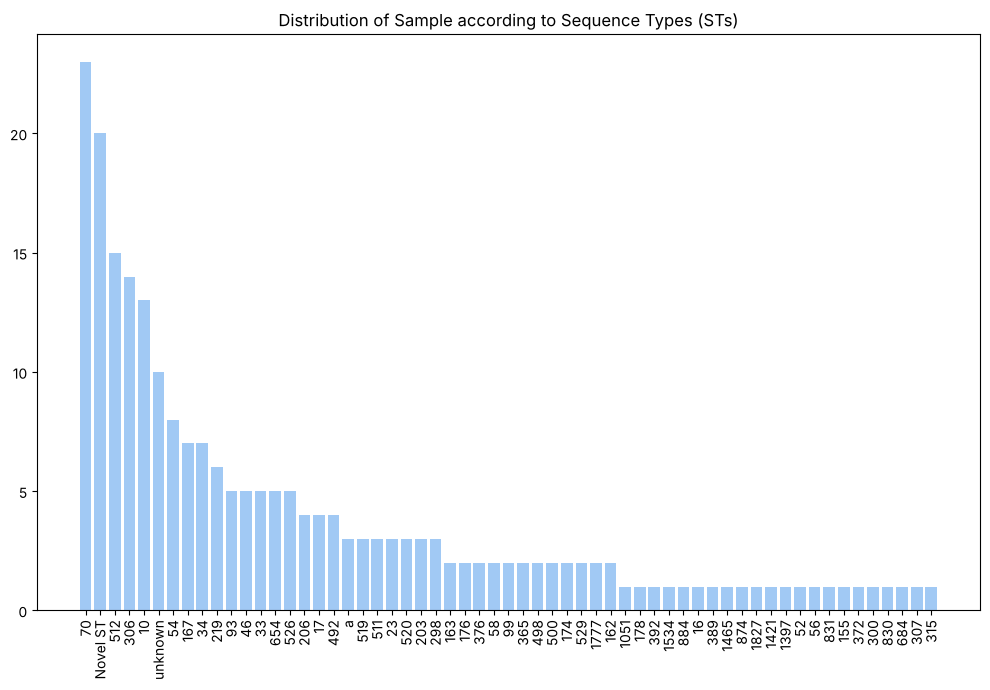

In [7]:
fig, axes = plt.subplots(figsize=(10, 7))

axes.bar(x=metadata["ST"].value_counts().sort_values(ascending=False).index,
        height=metadata["ST"].value_counts().sort_values(ascending=False).values)

plt.xticks(rotation=90)
plt.title("Distribution of Sample according to Sequence Types (STs)")
plt.tight_layout()
plt.show()

As for the SNP and CNV data, I will set aside sequence types **70**, **306**, **54**, and **46** for the test set.

This should provide us with a test set that contains around 50 samples and that isn't too diverse. More importantly, the model is not trained with strains from the lineages in the test set, and we can thus more accurately assess how well the model will perform on unseen data with this test set.

### **2.2 Splitting the test set**

In [8]:
# Identify test samples
test_mask = metadata["ST"].isin(["46", "54", "70", "306"])
print(f"There are {test_mask.sum()} strains with Sequence Types 46, 54, 70 and 306")

# Create the test set
sv_test = sv_data[test_mask]
profiles_test = profiles[test_mask]

print("\nTest data shape:")
print(sv_test.shape)
print(profiles_test.shape)
print("\nSXT distribution in the test set:")
print(profiles_test.value_counts())

There are 50 strains with Sequence Types 46, 54, 70 and 306

Test data shape:
(50, 3501)
(50, 1)

SXT distribution in the test set:
SXT_binary
0             30
1             20
Name: count, dtype: int64


### **2.3 Splitting the training set**
Let's now assign the leftover samples to a training set.

In [9]:
#create the "training and validation" set with the leftover values
sv_train = sv_data[~test_mask]
profiles_train = profiles[~test_mask]

print("\nTraining and validation data shape:")
print(sv_train.shape)
print(profiles_train.shape)
print("\nSXT distribution in the training set:")
print(profiles_train.value_counts())


Training and validation data shape:
(177, 3501)
(177, 1)

SXT distribution in the training set:
SXT_binary
1             103
0              74
Name: count, dtype: int64


### **2.4 Saving the data**

In [10]:
sv_test.to_csv("Data/sv_test.csv")
sv_train.to_csv("Data/sv_train.csv")

In [11]:
profiles_test.to_csv("Data/SXT_test.csv")
profiles_train.to_csv("Data/SXT_train.csv")